In [2]:
import math, random, time
from collections import Counter
import matplotlib.pyplot as plt

In [3]:
MOVS = [(1,2),(2,1),(-1,2),(-2,1),(1,-2),(2,-1),(-1,-2),(-2,-1)]

def vecinos_caballo(n):
    """Para cada casilla i = fila*n + col, bitmask de las casillas que ataca un caballo."""
    vec = []
    for f in range(n):
        for c in range(n):
            m = 0
            for df, dc in MOVS:
                ff, cc = f + df, c + dc
                if 0 <= ff < n and 0 <= cc < n:
                    m |= 1 << (ff * n + cc)
            vec.append(m)
    return vec

def contar_colocaciones(n, k):
    """Número de formas de colocar k caballos (indistinguibles) sin ataques en n×n."""
    vec, N = vecinos_caballo(n), n * n
    def rec(i, colocados, faltan):
        if faltan == 0:
            return 1
        if N - i < faltan:          # poda: no quedan casillas suficientes
            return 0
        total = rec(i + 1, colocados, faltan)            # no poner caballo en i
        if not (vec[i] & colocados):                     # poner caballo en i si es seguro
            total += rec(i + 1, colocados | (1 << i), faltan - 1)
        return total
    return rec(0, 0, k)

# Comparación: total de combinaciones vs colocaciones válidas
print(f"{'n':>2} {'k':>2} {'C(n²,k)':>10} {'válidas':>10} {'% válidas':>10}")
for n in (3, 4, 5):
    for k in range(2, 7):
        total = math.comb(n * n, k)
        validas = contar_colocaciones(n, k)
        print(f"{n:>2} {k:>2} {total:>10} {validas:>10} {100 * validas / total:>9.1f}%")

 n  k    C(n²,k)    válidas  % válidas
 3  2         36         28      77.8%
 3  3         84         36      42.9%
 3  4        126         18      14.3%
 3  5        126          2       1.6%
 3  6         84          0       0.0%
 4  2        120         96      80.0%
 4  3        560        276      49.3%
 4  4       1820        412      22.6%
 4  5       4368        340       7.8%
 4  6       8008        170       2.1%
 5  2        300        252      84.0%
 5  3       2300       1360      59.1%
 5  4      12650       4436      35.1%
 5  5      53130       9386      17.7%
 5  6     177100      13384       7.6%


n=1: máximo = 1 caballos (verificado)
n=2: máximo = 4 caballos (verificado)
n=3: máximo = 5 caballos (verificado)
n=4: máximo = 8 caballos (verificado)
n=5: máximo = 13 caballos (verificado)
n=6: máximo = 18 caballos (verificado)
n=7: máximo = 25 caballos (verificado)
n=8: máximo = 32 caballos (verificado)


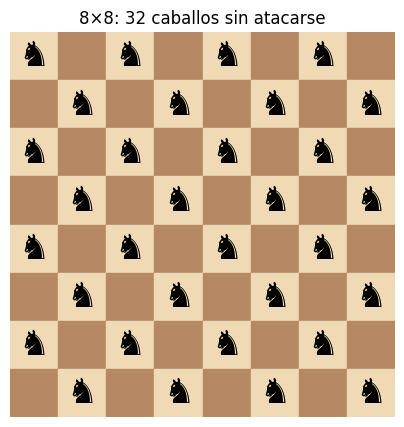

In [4]:
def max_caballos(n):
    if n == 1: return 1
    if n == 2: return 4
    return (n * n + 1) // 2

def construir_maximo(n):
    """Coloca el máximo de caballos usando solo las casillas de un color."""
    if n == 2:
        return [(0,0), (0,1), (1,0), (1,1)]
    return [(f, c) for f in range(n) for c in range(n) if (f + c) % 2 == 0]

def es_valido(n, pos):
    s = set(pos)
    return all((f + df, c + dc) not in s for f, c in pos for df, dc in MOVS)

def dibujar_caballos(n, pos, titulo=""):
    fig, ax = plt.subplots(figsize=(5, 5))
    for f in range(n):
        for c in range(n):
            ax.add_patch(plt.Rectangle((c, n - 1 - f), 1, 1, color="#f0d9b5" if (f + c) % 2 == 0 else "#b58863"))
    for f, c in pos:
        ax.text(c + 0.5, n - 1 - f + 0.5, "♞", ha="center", va="center", fontsize=200 / n, color="black")
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(titulo)
    plt.show()

for n in range(1, 9):
    pos = construir_maximo(n)
    assert es_valido(n, pos) and len(pos) == max_caballos(n)
    print(f"n={n}: máximo = {max_caballos(n)} caballos (verificado)")

dibujar_caballos(8, construir_maximo(8), "8×8: 32 caballos sin atacarse")

In [5]:
def conflictos(tab):
    """Energía = pares de reinas en la misma fila o diagonal (tab[col] = fila)."""
    filas = Counter(tab)
    d1 = Counter(c - r for c, r in enumerate(tab))
    d2 = Counter(c + r for c, r in enumerate(tab))
    return sum(v * (v - 1) // 2 for cnt in (filas, d1, d2) for v in cnt.values())

def recocido_simulado(n, T0=1.0, alpha=0.9995, T_min=0.02, max_iter=100_000, rnd=None):
    rnd = rnd or random.Random()
    tab = [rnd.randrange(n) for _ in range(n)]
    E, T = conflictos(tab), T0
    hist = [E]
    for it in range(max_iter):
        if E == 0:
            break
        c = rnd.randrange(n)
        fila_ant, fila_nueva = tab[c], rnd.randrange(n)
        if fila_nueva == fila_ant:
            continue
        tab[c] = fila_nueva
        E_nueva = conflictos(tab)
        dE = E_nueva - E
        if dE <= 0 or rnd.random() < math.exp(-dE / T):
            E = E_nueva                 # aceptar
        else:
            tab[c] = fila_ant           # rechazar
        T = max(T * alpha, T_min)       # enfriamiento geométrico
        hist.append(E)
    return tab, E, hist

def resolver(n, reinicios=30, seed=None, **kw):
    rnd = random.Random(seed)
    for r in range(1, reinicios + 1):
        tab, E, hist = recocido_simulado(n, rnd=rnd, **kw)
        if E == 0:
            return tab, hist, r
    return tab, hist, reinicios

def dibujar_reinas(tab, titulo=""):
    n = len(tab)
    fig, ax = plt.subplots(figsize=(5, 5))
    for f in range(n):
        for c in range(n):
            ax.add_patch(plt.Rectangle((c, n - 1 - f), 1, 1, color="#f0d9b5" if (f + c) % 2 == 0 else "#b58863"))
    for c, f in enumerate(tab):
        ax.text(c + 0.5, n - 1 - f + 0.5, "♛", ha="center", va="center", fontsize=200 / n, color="black")
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(titulo)
    plt.show()

n=8: conflictos finales = 0, intentos = 1, tiempo = 0.02 s
Solución (fila de la reina en cada columna): [1, 4, 6, 0, 2, 7, 5, 3]


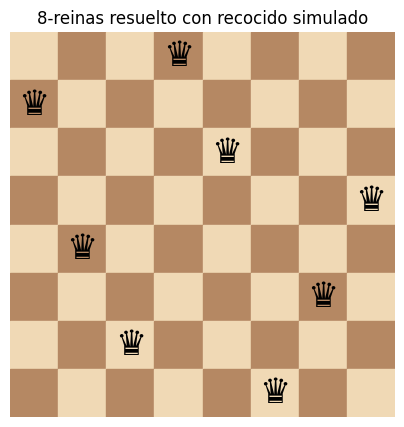

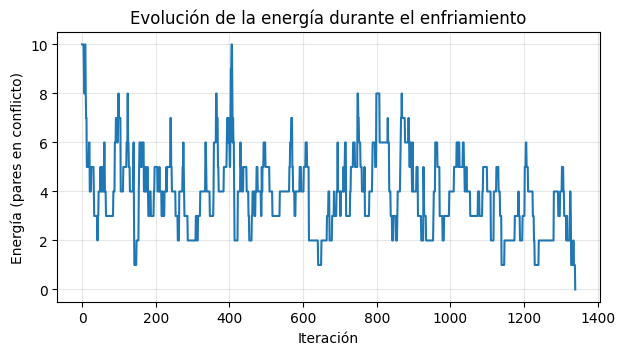

In [6]:
n = 8
t0 = time.time()
tab, hist, intentos = resolver(n, seed=42)
print(f"n={n}: conflictos finales = {conflictos(tab)}, intentos = {intentos}, tiempo = {time.time() - t0:.2f} s")
print("Solución (fila de la reina en cada columna):", tab)

dibujar_reinas(tab, f"{n}-reinas resuelto con recocido simulado")

plt.figure(figsize=(7, 3.5))
plt.plot(hist)
plt.xlabel("Iteración"); plt.ylabel("Energía (pares en conflicto)")
plt.title("Evolución de la energía durante el enfriamiento")
plt.grid(alpha=0.3); plt.show()

In [7]:
# Escalabilidad: distintos tamaños de tablero
print(f"{'n':>4} {'conflictos':>11} {'intentos':>9} {'tiempo (s)':>11}")
for n in (8, 16, 32, 64):
    t0 = time.time()
    tab, hist, intentos = resolver(n, seed=1, max_iter=200_000)
    print(f"{n:>4} {conflictos(tab):>11} {intentos:>9} {time.time() - t0:>11.2f}")

   n  conflictos  intentos  tiempo (s)
   8           0         1        0.04
  16           0         1        0.15
  32           0         1        0.35
  64           0         1        2.34
